# Fast 10-slider photo pipeline

This notebook loads a sample as color-managed sRGB, applies the same `PhotoEditor` used by the RL environment, displays the result, and benchmarks it. Actions are normalized to `[-1, 1]`; Exposure maps to ±5 EV and the other controls map to their Lightroom-style full slider range.

The pipeline is intended for rendered RGB inputs (JPEG/PNG). EXIF orientation and ICC conversion happen once at load time. Camera-specific RAW development needs the original sensor data and is intentionally outside this environment.

In [1]:
from pathlib import Path
import io
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageCms, ImageOps
import torch

root = Path.cwd().resolve()
while root != root.parent and not (root / 'src' / 'envs' / 'new_edit_photo.py').exists():
    root = root.parent
if not (root / 'src' / 'envs' / 'new_edit_photo.py').exists():
    raise RuntimeError('Run this notebook from inside the ai-photo-enhancer repository')
sys.path.insert(0, str(root))

from src.envs.new_edit_photo import PhotoEditor, SLIDER_ORDER

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Repository:', root)
print('Device:', device)
print('Action order:', SLIDER_ORDER)

Repository: /home/zakarianarjis/workspace/ai-photo-enhancer
Device: cuda
Action order: ('contrast', 'exposure', 'temp', 'tint', 'whites', 'blacks', 'highlights', 'shadows', 'vibrance', 'saturation')


In [2]:
def load_rendered_srgb(path: Path, max_edge: int | None = None):
    # Orientation and ICC handling are useful rendered-image metadata. They are
    # resolved once here, never inside the hot RL environment step.
    with Image.open(path) as opened:
        metadata = {
            'format': opened.format,
            'size': opened.size,
            'has_exif': bool(opened.getexif()),
            'has_icc_profile': bool(opened.info.get('icc_profile')),
        }
        image = ImageOps.exif_transpose(opened)
        icc = image.info.get('icc_profile')
        if icc:
            try:
                source_profile = ImageCms.ImageCmsProfile(io.BytesIO(icc))
                image = ImageCms.profileToProfile(
                    image, source_profile, ImageCms.createProfile('sRGB'), outputMode='RGB'
                )
                metadata['icc_converted_to_srgb'] = True
            except (OSError, ValueError):
                image = image.convert('RGB')
                metadata['icc_converted_to_srgb'] = False
        else:
            image = image.convert('RGB')
            metadata['icc_converted_to_srgb'] = False
        if max_edge and max(image.size) > max_edge:
            image.thumbnail((max_edge, max_edge), Image.Resampling.LANCZOS)
        array = np.asarray(image, dtype=np.float32) / 255.0
    return torch.from_numpy(array.copy()), metadata

IMAGE_PATH = root / 'src' / 'sample_images' / 'demo_sample.jpg'
MAX_EDGE = 1200  # Set to None to use the full-resolution file.
image, metadata = load_rendered_srgb(IMAGE_PATH, MAX_EDGE)
print(IMAGE_PATH.name, metadata, 'loaded tensor:', tuple(image.shape))

demo_sample.jpg {'format': 'JPEG', 'size': (1100, 619), 'has_exif': True, 'has_icc_profile': True, 'icc_converted_to_srgb': True} loaded tensor: (619, 1100, 3)


## Edit the controls

Change these values and rerun the next cells. Keeping names in a dictionary avoids action-order mistakes. A value of `0` is neutral.

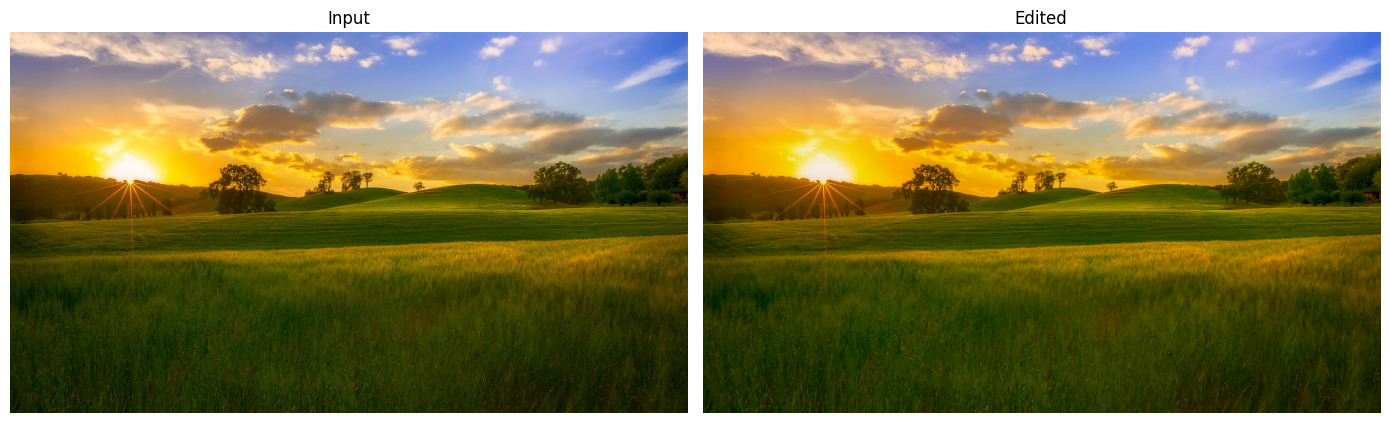

In [3]:
controls = {
    'temp': 0.08,
    'tint': 0.00,
    'vibrance': 0.25,
    'saturation': 0.05,
    'contrast': 0.12,
    'exposure': 0.05,  # normalized action: 0.05 means +0.25 EV
    'shadows': 0.22,
    'highlights': -0.28,
    'whites': 0.08,
    'blacks': -0.10,
}

editor = PhotoEditor('all').to(device).eval()
actions = torch.tensor([[controls[name] for name in editor.sliders]], device=device)
batch = image.unsqueeze(0).to(device)
edited = editor(batch, actions)[0].cpu()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(image)
axes[0].set_title('Input')
axes[1].imshow(edited)
axes[1].set_title('Edited')
for axis in axes:
    axis.axis('off')
plt.tight_layout()

## Timing

The first call includes setup/kernel warm-up and is excluded. CUDA is synchronized around the timed region so the number reflects completed work. The second benchmark uses the training-size resolution and batch size.

In [4]:
def synchronize():
    if device.type == 'cuda':
        torch.cuda.synchronize()

def benchmark(editor, images, params, repeats=50, warmup=10):
    for _ in range(warmup):
        editor(images, params)
    synchronize()
    started = time.perf_counter()
    for _ in range(repeats):
        editor(images, params)
    synchronize()
    elapsed_ms = (time.perf_counter() - started) * 1000 / repeats
    return elapsed_ms

preview_ms = benchmark(editor, batch, actions)
print(f'Preview {batch.shape[1]}x{batch.shape[2]}, batch 1: {preview_ms:.3f} ms/call')

TRAIN_SIZE = 224
TRAIN_BATCH = 64 if device.type == 'cuda' else 8
train_image = torch.nn.functional.interpolate(
    batch.permute(0, 3, 1, 2), size=(TRAIN_SIZE, TRAIN_SIZE), mode='bilinear', align_corners=False
).permute(0, 2, 3, 1).expand(TRAIN_BATCH, -1, -1, -1).contiguous()
train_actions = actions.expand(TRAIN_BATCH, -1).contiguous()
train_ms = benchmark(editor, train_image, train_actions, repeats=30, warmup=5)
print(f'Training {TRAIN_SIZE}x{TRAIN_SIZE}, batch {TRAIN_BATCH}: {train_ms:.3f} ms/call')
print(f'Per image: {train_ms / TRAIN_BATCH:.4f} ms')

Preview 619x1100, batch 1: 1.954 ms/call
Training 224x224, batch 64: 7.471 ms/call
Per image: 0.1167 ms


## Inspect one control at a time

This is useful for checking direction, strength, clipping, halos, and hue stability before training.

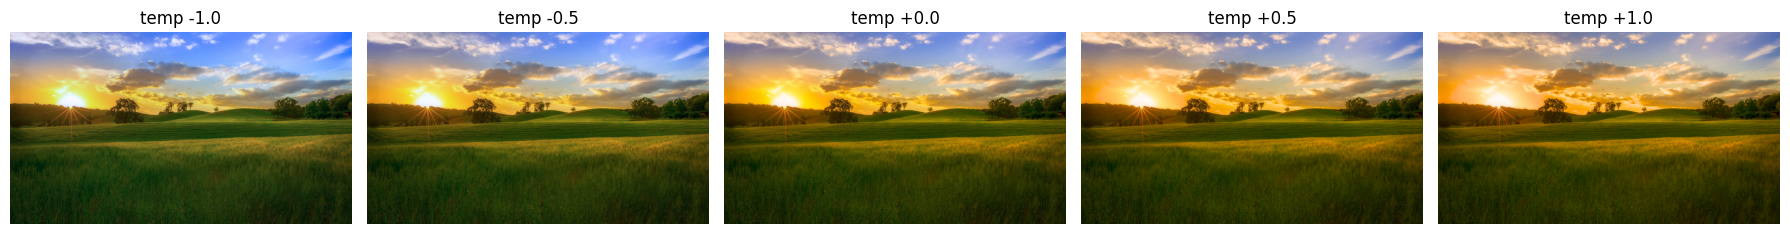

In [9]:
INSPECT = 'temp'
VALUES = (-1.0, -0.5, 0.0, 0.5, 1.0)
sweep = torch.zeros(len(VALUES), editor.num_parameters, device=device)
sweep[:, editor.sliders.index(INSPECT)] = torch.tensor(VALUES, device=device)
sweep_images = batch.expand(len(VALUES), -1, -1, -1)
sweep_output = editor(sweep_images, sweep).cpu()
fig, axes = plt.subplots(1, len(VALUES), figsize=(18, 5))
for axis, value, result in zip(axes, VALUES, sweep_output):
    axis.imshow(result)
    axis.set_title(f'{INSPECT} {value:+.1f}')
    axis.axis('off')
plt.tight_layout()